<a href="https://colab.research.google.com/github/suhasai/suhasdl/blob/main/Dog_Cat_Classification_Using_Mobile_net_Model(Deep_Learning).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install kaggle

In [2]:
#Configuring the Path of kaggle.json file
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

#importing The Dog vs Cat Datset From Kaggle

In [3]:
!kaggle competitions download -c dogs-vs-cats


In [4]:
!ls

dogs-vs-cats.zip  kaggle.json  sample_data


In [5]:
#Extracting the compressed dataset
from zipfile import ZipFile
dataset = '/content/dogs-vs-cats.zip'

with ZipFile(dataset,'r') as zip:
  zip.extractall()
  print('The dataset is extracted')

The dataset is extracted


In [6]:
# Extracting the Train.zip
from zipfile import ZipFile
dataset = '/content/train.zip'

with ZipFile(dataset,'r') as zip:
  zip.extractall()
  print('The dataset is extracted')

The dataset is extracted


In [7]:
import os
#counting the number of files  in train folder
path, dirs, files = next(os.walk('/content/train'))
file_count = len(files)
print('Number of images in train folder:',file_count)

Number of images in train folder: 25000


Printing the name of images

In [8]:
file_names = os.listdir('/content/train')
print(file_names)

['dog.6020.jpg', 'dog.10782.jpg', 'cat.7539.jpg', 'dog.9013.jpg', 'dog.5439.jpg', 'dog.1058.jpg', 'dog.4068.jpg', 'dog.12498.jpg', 'dog.1385.jpg', 'dog.2874.jpg', 'dog.11733.jpg', 'dog.8157.jpg', 'cat.4612.jpg', 'cat.10396.jpg', 'dog.1320.jpg', 'cat.1755.jpg', 'cat.8098.jpg', 'dog.18.jpg', 'cat.7462.jpg', 'cat.7034.jpg', 'cat.1571.jpg', 'dog.2995.jpg', 'dog.4076.jpg', 'cat.10488.jpg', 'dog.3489.jpg', 'dog.446.jpg', 'cat.9450.jpg', 'cat.10198.jpg', 'dog.11468.jpg', 'cat.5605.jpg', 'dog.2154.jpg', 'dog.1461.jpg', 'dog.3781.jpg', 'dog.132.jpg', 'dog.4414.jpg', 'dog.9208.jpg', 'cat.1698.jpg', 'dog.5333.jpg', 'cat.4067.jpg', 'cat.9213.jpg', 'dog.11729.jpg', 'cat.647.jpg', 'cat.8310.jpg', 'cat.8034.jpg', 'cat.10999.jpg', 'dog.2033.jpg', 'dog.4165.jpg', 'cat.8570.jpg', 'cat.9981.jpg', 'cat.3284.jpg', 'dog.6098.jpg', 'dog.11017.jpg', 'cat.1286.jpg', 'dog.7415.jpg', 'dog.10794.jpg', 'cat.9672.jpg', 'dog.7878.jpg', 'cat.5210.jpg', 'cat.1090.jpg', 'dog.4198.jpg', 'dog.5897.jpg', 'dog.459.jpg', 'd

Importing the Depenedencies

In [9]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from sklearn.model_selection import train_test_split
from google.colab.patches import cv2_imshow

Displaying the images of Dog and Cats

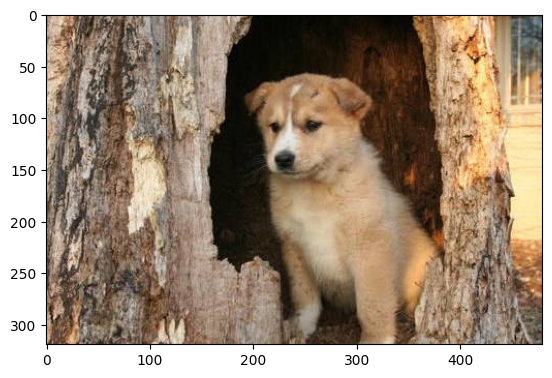

In [10]:
img = mpimg.imread('/content/train/dog.10782.jpg')
imgplot = plt.imshow(img)
plt.show()

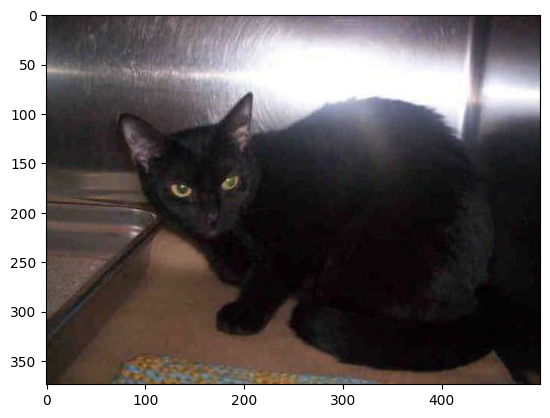

In [11]:
img = mpimg.imread('/content/train/cat.7539.jpg')
imgplot = plt.imshow(img)
plt.show()

In [12]:
file_names = os.listdir('/content/train/')
for i in range(5):

  name = file_names[i]
  print(name[0:3])

dog
dog
cat
dog
dog


In [13]:
file_names = os.listdir('/content/train/')

dog_count = 0
cat_count = 0

for img_file in file_names:

  name = img_file[0:3]

  if name == 'dog':
    dog_count += 1
  else:
    cat_count += 1

print('Number of dogs:',dog_count)
print('Number of cats:',cat_count)


Number of dogs: 12500
Number of cats: 12500


Resizing all images

In [14]:
#Creating a Directory for this Resized images
os.mkdir('/content/resized_images')

In [15]:
original_folder = '/content/train/'
resized_folder = '/content/resized_images/'

for i in range(2000):

  filename = os.listdir(original_folder)[i]
  img_path = original_folder + filename

  img = Image.open(img_path)
  img = img.resize((224,224))
  img = img.convert('RGB')

  newImgpath = resized_folder + filename
  img.save(newImgpath)

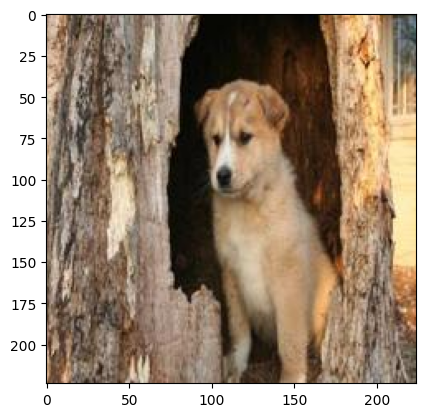

In [16]:
img = mpimg.imread('/content/resized_images/dog.10782.jpg')
imgplot = plt.imshow(img)
plt.show()

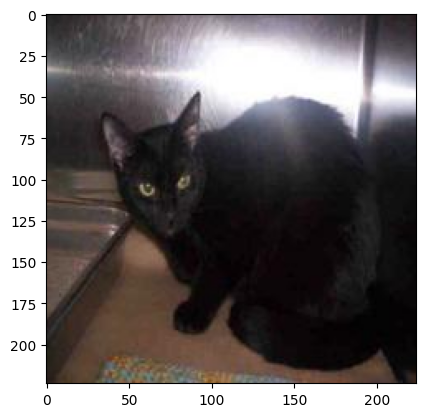

In [17]:
img = mpimg.imread('/content/resized_images/cat.7539.jpg')
imgplot = plt.imshow(img)
plt.show()

Creating Lables for Resized Images of Dogs and cats
Cat ---> 0
dog ---> 1

In [30]:
# creatinng a for loop to assaign lables
filenames = os.listdir('/content/resized_images/')

labels = []

for i in range(2000):

  file_name = filenames[i]
  label = file_name[0:3]

  if label == 'dog':
    labels.append(1)

  else:
    labels.append(0)


In [31]:
print(file_names[0:5])
print(len(labels))

['dog.6020.jpg', 'dog.10782.jpg', 'cat.7539.jpg', 'dog.9013.jpg', 'dog.5439.jpg']
2000


In [32]:
print(labels[0:5])
print(len(labels))

[1, 1, 0, 1, 1]
2000


In [33]:
# counting images of dogs and cats inn 2000 images
values, counts = np.unique(labels, return_counts=True)
print(values)
print(counts)

[0 1]
[1029  971]


Covert All resized_images into numpy array to feed a model

In [34]:
import cv2
import glob

In [35]:
image_directory = '/content/resized_images/'
image_extension = ['png', 'jpg']

files = []

[files.extend(glob.glob(image_directory + '*.' + e)) for e in image_extension]

dog_cat_images = np.asarray([cv2.imread(file) for file in files])

In [36]:
print(dog_cat_images)

[[[[ 65  98  77]
   [ 65  98  77]
   [ 75 103  84]
   ...
   [ 38  90 102]
   [ 31  78  92]
   [ 37  83 100]]

  [[ 75 108  87]
   [ 71 102  81]
   [ 70  98  79]
   ...
   [ 51 103 115]
   [ 51  97 114]
   [ 42  88 105]]

  [[ 68  99  78]
   [ 69 100  79]
   [ 71  99  80]
   ...
   [ 59 111 124]
   [ 65 111 129]
   [ 42  88 106]]

  ...

  [[ 10  71  67]
   [ 55 115 114]
   [ 79 137 136]
   ...
   [ 82 135 156]
   [ 32  82 102]
   [  3  53  73]]

  [[ 67 132 133]
   [ 46 110 111]
   [ 17  78  82]
   ...
   [ 63 116 137]
   [ 43  93 113]
   [ 27  77  97]]

  [[ 43 110 113]
   [ 23  90  93]
   [ 47 109 117]
   ...
   [129 182 203]
   [127 176 198]
   [ 94 144 164]]]


 [[[ 96 114 143]
   [150 169 196]
   [176 190 218]
   ...
   [ 56  65  55]
   [ 60  64  52]
   [ 73  76  61]]

  [[107 125 154]
   [134 153 180]
   [154 171 198]
   ...
   [ 76  81  72]
   [ 70  72  60]
   [ 75  75  61]]

  [[107 125 154]
   [126 145 172]
   [143 160 187]
   ...
   [118 117 107]
   [105 102  88]
   [103  98

In [37]:
type(dog_cat_images)

numpy.ndarray

In [38]:
print(dog_cat_images.shape)

(2000, 224, 224, 3)


In [39]:
x = dog_cat_images
y = np.asarray(labels)

train test split

In [40]:
x_train, x_test, y_train_test, y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [41]:
print(x_train.shape)
print(x_test.shape)
print(y_train_test.shape)
print(y_test.shape)

(1600, 224, 224, 3)
(400, 224, 224, 3)
(1600,)
(400,)


1600 ----> training images
400 ------> test images

Before data feedinng , have to scale all images to below 255 pixels

In [42]:
# Scaling the data
x_train_scaled = x_train/255
x_test_scaled = x_test/255

In [43]:
print(x_train_scaled)
print(x_test_scaled)

[[[[0.04705882 0.04313725 0.07843137]
   [0.04705882 0.04313725 0.07843137]
   [0.04705882 0.04313725 0.07843137]
   ...
   [0.25882353 0.29803922 0.36470588]
   [0.25490196 0.29411765 0.36078431]
   [0.24705882 0.28627451 0.35294118]]

  [[0.0627451  0.05882353 0.09411765]
   [0.05882353 0.05490196 0.09019608]
   [0.05882353 0.05490196 0.09019608]
   ...
   [0.26666667 0.30588235 0.37647059]
   [0.27058824 0.30980392 0.38039216]
   [0.2627451  0.30980392 0.38039216]]

  [[0.07843137 0.0745098  0.10980392]
   [0.07843137 0.0745098  0.10980392]
   [0.07843137 0.0745098  0.10980392]
   ...
   [0.2627451  0.30588235 0.38431373]
   [0.2745098  0.31764706 0.39607843]
   [0.27058824 0.3254902  0.4       ]]

  ...

  [[0.8745098  0.91764706 0.87843137]
   [0.86666667 0.90980392 0.87058824]
   [0.85098039 0.90588235 0.85882353]
   ...
   [0.82745098 0.78431373 0.70588235]
   [0.83529412 0.79215686 0.71372549]
   [0.84313725 0.8        0.72156863]]

  [[0.85882353 0.90196078 0.8627451 ]
   [0.8

Building Nueral Network

In [50]:
import tensorflow as tf
import tensorflow_hub as hub

In [49]:
mobilenet_model = hub.load('https://tfhub.dev/google/tf2-preview/mobilenet_v2/feature_vector/4')

pretained_model = hub.KerasLayer(mobilenet_model,input_shape=(224,224,3),trainable=False)

In [51]:

num_of_classes = 2

# Wrap the hub.KerasLayer in a Lambda layer
model = tf.keras.Sequential([
    tf.keras.layers.InputLayer(input_shape=(224, 224, 3)),
    tf.keras.layers.Lambda(lambda x: hub.KerasLayer(mobilenet_model, trainable=False)(x)),  # Wrap in Lambda
    tf.keras.layers.Dense(num_of_classes)
])

model.summary()


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                      │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 2)                   │           2,562 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,562 (10.01 KB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 0 (0.00 B)

In [53]:
model.compile(

    optimizer ='adam',
    loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics = ['acc']
)

In [57]:
model.fit(x_train_scaled,y_train_test,epochs=5)

Epoch 1/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 51s 1s/step - acc: 0.9750 - loss: 0.0776
Epoch 2/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 85s 1s/step - acc: 0.9653 - loss: 0.0755
Epoch 3/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 77s 992ms/step - acc: 0.9783 - loss: 0.0592
Epoch 4/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 85s 1s/step - acc: 0.9916 - loss: 0.0367
Epoch 5/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - acc: 0.9898 - loss: 0.0358


In [58]:
score, acc = model.evaluate(x_test_scaled,y_test)
print('Test loss:',score)
print('Test accuracy:',acc)

13/13 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - acc: 0.9694 - loss: 0.0763  
Test loss: 0.06401466578245163
Test accuracy: 0.9750000238418579


Predictive System

Path of image to be predicted: /content/cat.jpg


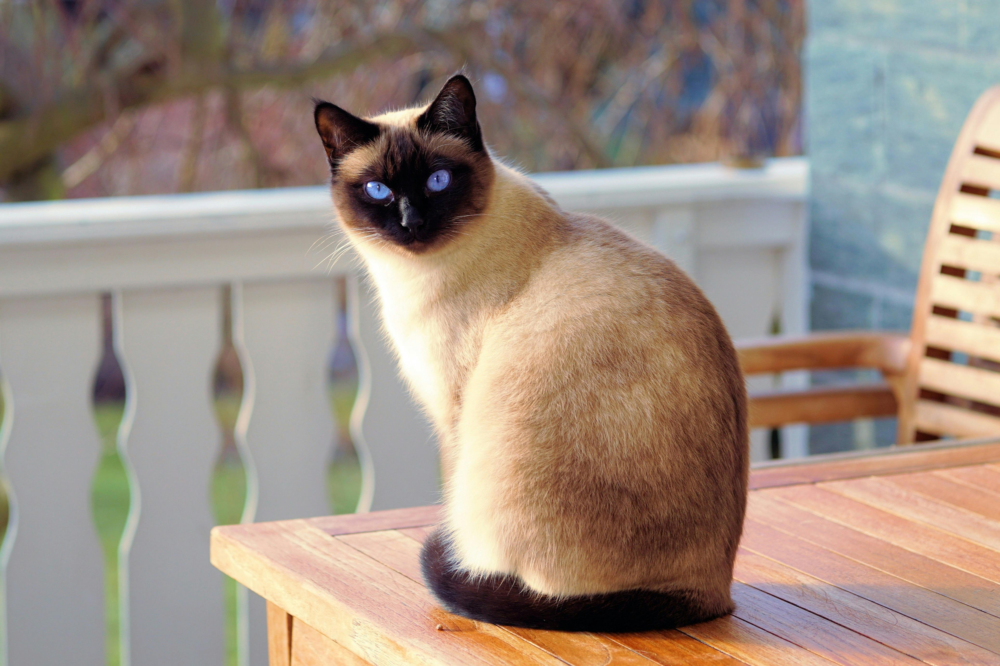

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
The image is a cat
[[ 3.117969  -3.8992035]]
0
The image is a cat


In [60]:
input_image_path = input('Path of image to be predicted: ')

input_image = cv2.imread(input_image_path)

cv2_imshow(input_image)

input_image_resize = cv2.resize(input_image,(224,224))

input_image_scaled = input_image_resize/255

image_reshaped = np.reshape(input_image_scaled,[1,224,224,3])

input_prediction = model.predict(image_reshaped)

input_pred_label = np.argmax(input_prediction)

if input_pred_label == 0:
  print('The image is a cat')
else:
  print('The image is a dog')

print(input_prediction)

input_pred_label = np.argmax(input_prediction)

print(input_pred_label)

if input_pred_label == 0:
  print('The image is a cat')

else:
  print('The image is a dog')